In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import math
import time
import os

SEED = 5286

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Selected device:", device)

PyTorch version: 2.11.0+cu130
GPU available: True
Selected device: cuda


In [3]:
from pathlib import Path

# Project directories
BASE_DIR = Path("Problem2_Results")
FIGURES_DIR = BASE_DIR / "figures"

# Create folders if they do not exist
BASE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", BASE_DIR)
print("Figures directory:", FIGURES_DIR)

Results directory: Problem2_Results
Figures directory: Problem2_Results/figures


In [4]:
!pip install -q gdown

In [2]:
# import os

# BASE_DIR = "/kaggle/working/problem2"
# FIGURES_DIR = os.path.join(BASE_DIR, "figures")

# os.makedirs(FIGURES_DIR, exist_ok=True)

# RESULTS_FILE = os.path.join(BASE_DIR, "results.csv")

# print("Results folder:", BASE_DIR)
# print("Figures folder:", FIGURES_DIR)
# print("CSV file:", RESULTS_FILE)

In [9]:
def scaled_dot_product_attention(Q, K, V, mask=None):

    d_k = Q.shape[-1]

    scores = torch.matmul(Q, K.transpose(-2, -1))
    scores = scores / (d_k ** 0.5)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))

    weights = torch.softmax(scores, dim=-1)

    output = torch.matmul(weights, V)

    return output, weights

In [10]:
# Create sample tensors
Q = torch.randn(2, 4, 8).to(device)
K = torch.randn(2, 4, 8).to(device)
V = torch.randn(2, 4, 8).to(device)

# Calculate attention
output, weights = scaled_dot_product_attention(Q, K, V)

print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)
print("Output:", output)

Output shape: torch.Size([2, 4, 8])
Attention weights shape: torch.Size([2, 4, 4])
Output: tensor([[[ 0.9242, -0.8905, -0.3060, -1.1987,  0.6851, -0.8419,  1.0300,
          -0.7122],
         [ 0.7453,  0.8584, -0.0901, -0.8157, -0.2682, -0.8272,  0.5281,
          -0.3700],
         [ 0.8968,  0.4898, -0.3655, -1.2774, -0.1434, -0.7069,  0.8078,
          -0.0698],
         [ 0.8086, -0.9675, -0.1939, -0.9543,  0.2631, -1.0519,  0.8816,
          -0.6035]],

        [[-0.5905,  0.5653, -0.7245, -0.2535, -0.0538,  0.1644,  0.4403,
           0.1999],
         [ 0.1786,  0.7268, -0.4781, -0.6199, -0.6511,  0.1073, -0.2331,
          -1.1680],
         [-0.7052,  0.4579, -0.6794,  0.0296, -0.3182,  0.6304,  0.4288,
          -0.1004],
         [ 0.5211,  0.7345, -0.2911, -0.4961, -1.2804,  0.5150, -0.6454,
          -2.2918]]], device='cuda:0')


In [11]:
# Check whether attention weights sum to 1
print("Sum of attention weights:")

print(weights.sum(dim=-1))

# Check output values
print("\nAre all output values finite?")
print(torch.isfinite(output).all().item())

Sum of attention weights:
tensor([[1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000]], device='cuda:0')

Are all output values finite?
True


In [13]:
# Create a causal mask (4 x 4)
seq_len = Q.shape[1]

mask = torch.tril(
    torch.ones(seq_len, seq_len, device=Q.device)
)

# Apply attention with mask
masked_output, masked_weights = scaled_dot_product_attention(
    Q, K, V, mask
)

print("Masked attention weights:")
print(masked_weights)

# Check future positions only
future_positions = torch.triu(
    torch.ones(seq_len, seq_len, dtype=torch.bool, device=Q.device),
    diagonal=1
)

future_weights = masked_weights.masked_select(
    future_positions.unsqueeze(0).expand(Q.shape[0], -1, -1)
)

print("All future attention weights are zero:")
print(torch.allclose(future_weights, torch.zeros_like(future_weights)))

Masked attention weights:
tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.5899, 0.4101, 0.0000, 0.0000],
         [0.1446, 0.5012, 0.3542, 0.0000],
         [0.0937, 0.0251, 0.5198, 0.3614]],

        [[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3277, 0.6723, 0.0000, 0.0000],
         [0.6748, 0.1365, 0.1888, 0.0000],
         [0.0166, 0.0036, 0.9499, 0.0299]]], device='cuda:0')
All future attention weights are zero:
True


In [14]:
# Compare our attention with PyTorch's reference implementation

import torch.nn.functional as F

# Use the same Q, K and V tensors
our_output, our_weights = scaled_dot_product_attention(Q, K, V)

# PyTorch reference output (without a mask)
reference_output = F.scaled_dot_product_attention(Q, K, V)

# Check whether both outputs are almost equal
difference = torch.max(torch.abs(our_output - reference_output)).item()

print("Maximum difference:", difference)
print("Attention matches PyTorch:", difference < 1e-5)

assert difference < 1e-5, "Attention output does not match!"
print("Test passed!")

Maximum difference: 1.4901161193847656e-07
Attention matches PyTorch: True
Test passed!


In [15]:
# P2.1 - Hand-checkable 3-token attention example

Q_small = torch.tensor([[
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0]
]], device=device)

K_small = Q_small.clone()
V_small = Q_small.clone()

# Calculate attention using our own function
output, weights = scaled_dot_product_attention(
    Q_small, K_small, V_small
)

print("Attention weights:")
print(weights)

print("\nAttention output:")
print(output)

Attention weights:
tensor([[[0.4011, 0.1978, 0.4011],
         [0.1978, 0.4011, 0.4011],
         [0.2483, 0.2483, 0.5035]]], device='cuda:0')

Attention output:
tensor([[[0.8022, 0.5989],
         [0.5989, 0.8022],
         [0.7517, 0.7517]]], device='cuda:0')


In [16]:
# P2.1 - Compare our attention with PyTorch

import torch.nn.functional as F

pytorch_output = F.scaled_dot_product_attention(
    Q_small, K_small, V_small
)

difference = torch.max(
    torch.abs(output - pytorch_output)
).item()

print("Maximum difference:", difference)
print("Matches PyTorch:", difference < 1e-5)

assert difference < 1e-5
print("Test passed!")

Maximum difference: 0.0
Matches PyTorch: True
Test passed!


In [17]:
# P2.1 - Test causal masking

# Create a lower-triangular mask
causal_mask = torch.tril(
    torch.ones(3, 3, device=device)
)

# Calculate attention using the causal mask
masked_output, masked_attention_weights = scaled_dot_product_attention(
    Q_small,
    K_small,
    V_small,
    causal_mask
)

print("Causal attention weights:")
print(masked_attention_weights)

# Check that future tokens receive zero attention
future_attention_weights = masked_attention_weights[
    :, torch.triu(torch.ones(3, 3, device=device), diagonal=1).bool()
]

print("\nAll future attention weights are zero:")
print(torch.allclose(
    future_attention_weights,
    torch.zeros_like(future_attention_weights)
))

assert torch.allclose(
    future_attention_weights,
    torch.zeros_like(future_attention_weights)
)

print("Causal mask test passed!")

Causal attention weights:
tensor([[[1.0000, 0.0000, 0.0000],
         [0.3302, 0.6698, 0.0000],
         [0.2483, 0.2483, 0.5035]]], device='cuda:0')

All future attention weights are zero:
True
Causal mask test passed!


### P2.2 - Multi-Head Attention from Scratch

In [18]:
# P2.2 - Multi-Head Attention from Scratch

import torch.nn as nn

class MultiHeadAttention(nn.Module):

    def __init__(self, embedding_dimension, number_of_heads):
        super().__init__()

        assert embedding_dimension % number_of_heads == 0

        self.embedding_dimension = embedding_dimension
        self.number_of_heads = number_of_heads
        self.head_dimension = embedding_dimension // number_of_heads

        # Linear layers for Query, Key, Value and final output
        self.query_layer = nn.Linear(embedding_dimension, embedding_dimension)
        self.key_layer = nn.Linear(embedding_dimension, embedding_dimension)
        self.value_layer = nn.Linear(embedding_dimension, embedding_dimension)
        self.output_layer = nn.Linear(embedding_dimension, embedding_dimension)

    def forward(self, input_tensor):

        batch_size, sequence_length, _ = input_tensor.shape

        # Create Query, Key and Value
        query = self.query_layer(input_tensor)
        key = self.key_layer(input_tensor)
        value = self.value_layer(input_tensor)

        # Split into multiple heads
        query = query.view(
            batch_size, sequence_length,
            self.number_of_heads, self.head_dimension
        ).transpose(1, 2)

        key = key.view(
            batch_size, sequence_length,
            self.number_of_heads, self.head_dimension
        ).transpose(1, 2)

        value = value.view(
            batch_size, sequence_length,
            self.number_of_heads, self.head_dimension
        ).transpose(1, 2)

        # Apply attention
        attention_output, attention_weights = scaled_dot_product_attention(
            query, key, value
        )

        # Combine all heads
        attention_output = attention_output.transpose(1, 2).contiguous()

        attention_output = attention_output.view(
            batch_size, sequence_length, self.embedding_dimension
        )

        # Final linear transformation
        output = self.output_layer(attention_output)

        return output, attention_weights

In [19]:
# P2.2 - Test Multi-Head Attention

embedding_dimension = 128
number_of_heads = 4
batch_size = 2
sequence_length = 10

# Create sample input
sample_input = torch.randn(
    batch_size,
    sequence_length,
    embedding_dimension,
    device=device
)

# Create the multi-head attention model
attention_model = MultiHeadAttention(
    embedding_dimension,
    number_of_heads
).to(device)

# Run the model
attention_output, attention_weights = attention_model(sample_input)

# Check output dimensions
print("Input shape:", sample_input.shape)
print("Output shape:", attention_output.shape)
print("Attention weights shape:", attention_weights.shape)

# Verify dimensions
assert attention_output.shape == (2, 10, 128)
assert attention_weights.shape == (2, 4, 10, 10)

print("\nMulti-Head Attention test passed!")

Input shape: torch.Size([2, 10, 128])
Output shape: torch.Size([2, 10, 128])
Attention weights shape: torch.Size([2, 4, 10, 10])

Multi-Head Attention test passed!


### P2.3: Position-wise Feed-Forward Network

In [20]:
class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)


# Test the feed-forward network
feed_forward = PositionWiseFeedForward(
    d_model=128,
    d_ff=512
).to(device)

input_tensor = torch.randn(2, 10, 128).to(device)

output_tensor = feed_forward(input_tensor)

print("Input shape:", input_tensor.shape)
print("Output shape:", output_tensor.shape)

assert output_tensor.shape == input_tensor.shape

print("Feed-Forward Network test passed!")

Input shape: torch.Size([2, 10, 128])
Output shape: torch.Size([2, 10, 128])
Feed-Forward Network test passed!


### P2.4: Transformer Encoder Block

In [107]:

class TransformerEncoderBlock(nn.Module):

    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        # Multi-head self-attention
        self.attention = MultiHeadAttention(d_model, num_heads)

        # Position-wise feed-forward network
        self.feed_forward = PositionWiseFeedForward(d_model, d_ff)

        # Layer normalization (Pre-LN)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # Dropout
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):

        # --------------------------------
        # 1. Pre-LayerNorm before attention
        # --------------------------------
        normalized_x = self.norm1(x)

        attention_output, attention_weights = self.attention(
            normalized_x
        )

        # Residual connection
        x = x + self.dropout(attention_output)

        # --------------------------------
        # 2. Pre-LayerNorm before FFN
        # --------------------------------
        normalized_x = self.norm2(x)

        feed_forward_output = self.feed_forward(normalized_x)

        # Residual connection
        x = x + self.dropout(feed_forward_output)

        return x, attention_weights


print("Pre-LayerNorm Transformer Encoder Block defined successfully!")


Pre-LayerNorm Transformer Encoder Block defined successfully!


In [108]:

# Create Transformer Encoder Block

encoder = TransformerEncoderBlock(
    d_model=128,
    num_heads=4,
    d_ff=512,
    dropout=0.1
).to(device)

# Create sample input
input_tensor = torch.randn(2, 10, 128).to(device)

# Forward pass
output_tensor, attention_weights = encoder(input_tensor)

# Display shapes
print("Input shape:", input_tensor.shape)
print("Output shape:", output_tensor.shape)
print("Attention weights shape:", attention_weights.shape)

# Verify output dimensions
assert output_tensor.shape == input_tensor.shape
assert attention_weights.shape == (2, 4, 10, 10)

print("\nAll encoder shape tests passed!")


Input shape: torch.Size([2, 10, 128])
Output shape: torch.Size([2, 10, 128])
Attention weights shape: torch.Size([2, 4, 10, 10])

All encoder shape tests passed!


### P2.5: Complete Transformer Model

In [24]:
class TransformerModel(nn.Module):
    def __init__(
        self,
        input_dim,
        d_model,
        num_heads,
        d_ff,
        num_layers,
        output_dim
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_dim, d_model)

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

        self.output_layer = nn.Linear(d_model, output_dim)

    def forward(self, x):
        x = self.input_projection(x)

        for encoder_layer in self.encoder_layers:
            x, _ = encoder_layer(x)

        # Use the last time step for prediction
        x = x[:, -1, :]

        return self.output_layer(x)


# Test the complete Transformer model
transformer_model = TransformerModel(
    input_dim=64,
    d_model=128,
    num_heads=4,
    d_ff=512,
    num_layers=2,
    output_dim=10
).to(device)

input_tensor = torch.randn(2, 10, 64).to(device)

output_tensor = transformer_model(input_tensor)

print("Input shape:", input_tensor.shape)
print("Output shape:", output_tensor.shape)

assert output_tensor.shape == (2, 10)

print("Complete Transformer Model test passed!")

Input shape: torch.Size([2, 10, 64])
Output shape: torch.Size([2, 10])
Complete Transformer Model test passed!


In [25]:
print("Device:", device)

print("HAR data available:", "har_experiments" in globals())

if "har_experiments" in globals():
    print("Available seeds:", list(har_experiments.keys()))

Device: cuda
HAR data available: False


In [26]:

import glob
import os

har_files = glob.glob(
    "/kaggle/input/**/har_experiments.npz",
    recursive=True
)

print("HAR files found:", har_files)


HAR files found: ['/kaggle/input/datasets/samriddhimehta/har-problem1-data/har_experiments.npz']


In [27]:

import numpy as np

har_data = np.load(har_files[0])

har_experiments = {}

for seed in [42, 123, 2026]:
    har_experiments[seed] = {
        "X_train": har_data[f"{seed}_X_train"],
        "y_train": har_data[f"{seed}_y_train"],
        "X_val": har_data[f"{seed}_X_val"],
        "y_val": har_data[f"{seed}_y_val"],
        "X_test": har_data[f"{seed}_X_test"],
        "y_test": har_data[f"{seed}_y_test"],
    }

print("HAR data loaded successfully!")

for seed, exp in har_experiments.items():
    print(
        f"Seed {seed}:",
        "Train:", exp["X_train"].shape,
        "Validation:", exp["X_val"].shape,
        "Test:", exp["X_test"].shape
    )


HAR data loaded successfully!
Seed 42: Train: (5952, 128, 9) Validation: (1400, 128, 9) Test: (2947, 128, 9)
Seed 123: Train: (5896, 128, 9) Validation: (1456, 128, 9) Test: (2947, 128, 9)
Seed 2026: Train: (5950, 128, 9) Validation: (1402, 128, 9) Test: (2947, 128, 9)


In [28]:

import torch
import numpy as np

# Check the shape and label range for each seed
for seed, exp in har_experiments.items():
    print(f"\nSeed: {seed}")
    print("Train labels:", np.unique(exp["y_train"]))
    print("Validation labels:", np.unique(exp["y_val"]))
    print("Test labels:", np.unique(exp["y_test"]))

# Convert the first seed's data to PyTorch tensors
seed = 42
exp = har_experiments[seed]

X_train = torch.tensor(exp["X_train"], dtype=torch.float32, device=device)
y_train = torch.tensor(exp["y_train"], dtype=torch.long, device=device)

X_val = torch.tensor(exp["X_val"], dtype=torch.float32, device=device)
y_val = torch.tensor(exp["y_val"], dtype=torch.long, device=device)

X_test = torch.tensor(exp["X_test"], dtype=torch.float32, device=device)
y_test = torch.tensor(exp["y_test"], dtype=torch.long, device=device)

print("\nTensor conversion successful!")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Device:", X_train.device)



Seed: 42
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]

Seed: 123
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]

Seed: 2026
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]

Tensor conversion successful!
X_train: torch.Size([5952, 128, 9])
y_train: torch.Size([5952])
X_val: torch.Size([1400, 128, 9])
X_test: torch.Size([2947, 128, 9])
Device: cuda:0


In [29]:

# Inspect existing Transformer components

for name, obj in globals().copy().items():
    if isinstance(obj, type) and (
        "Transformer" in name or
        "Encoder" in name or
        "Attention" in name
    ):
        print(name)


MultiHeadAttention
TransformerEncoderBlock
TransformerModel


In [31]:

import inspect

print("TransformerModel constructor:")
print(inspect.signature(TransformerModel))

print("\nTransformerModel forward:")
print(inspect.signature(TransformerModel.forward))

print("\nTransformerEncoderBlock constructor:")
print(inspect.signature(TransformerEncoderBlock))

print("\nMultiHeadAttention constructor:")
print(inspect.signature(MultiHeadAttention))

print("\nModel methods:")
print(TransformerModel.__dict__.keys())


TransformerModel constructor:
(input_dim, d_model, num_heads, d_ff, num_layers, output_dim)

TransformerModel forward:
(self, x)

TransformerEncoderBlock constructor:
(d_model, num_heads, d_ff, dropout=0.1)

MultiHeadAttention constructor:
(embedding_dimension, number_of_heads)

Model methods:
dict_keys(['__module__', '__firstlineno__', '__init__', 'forward', '__static_attributes__', '__doc__'])


In [32]:

# Display the existing Transformer architecture

print("Transformer model:")
print(transformer_model)

print("\nEncoder block forward:")
import inspect
print(inspect.signature(TransformerEncoderBlock.forward))

print("\nAttention forward:")
print(inspect.signature(MultiHeadAttention.forward))


Transformer model:
TransformerModel(
  (input_projection): Linear(in_features=64, out_features=128, bias=True)
  (encoder_layers): ModuleList(
    (0-1): 2 x TransformerEncoderBlock(
      (attention): MultiHeadAttention(
        (query_layer): Linear(in_features=128, out_features=128, bias=True)
        (key_layer): Linear(in_features=128, out_features=128, bias=True)
        (value_layer): Linear(in_features=128, out_features=128, bias=True)
        (output_layer): Linear(in_features=128, out_features=128, bias=True)
      )
      (feed_forward): PositionWiseFeedForward(
        (network): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): ReLU()
          (2): Linear(in_features=512, out_features=128, bias=True)
        )
      )
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (output_layer): 

In [33]:

# Inspect the existing encoder and attention attributes

print("Encoder attributes:")
print(transformer_model.encoder_layers[0])

print("\nAttention attributes:")
print(vars(transformer_model.encoder_layers[0].attention))


Encoder attributes:
TransformerEncoderBlock(
  (attention): MultiHeadAttention(
    (query_layer): Linear(in_features=128, out_features=128, bias=True)
    (key_layer): Linear(in_features=128, out_features=128, bias=True)
    (value_layer): Linear(in_features=128, out_features=128, bias=True)
    (output_layer): Linear(in_features=128, out_features=128, bias=True)
  )
  (feed_forward): PositionWiseFeedForward(
    (network): Sequential(
      (0): Linear(in_features=128, out_features=512, bias=True)
      (1): ReLU()
      (2): Linear(in_features=512, out_features=128, bias=True)
    )
  )
  (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

Attention attributes:
{'training': True, '_parameters': {}, '_buffers': {}, '_non_persistent_buffers_set': set(), '_backward_pre_hooks': OrderedDict(), '_backward_hooks': OrderedDict(), '_is_full_backward_hook': None, '_forward

In [111]:
import torch
import torch.nn as nn

class HARTransformerClassifier(nn.Module):
    def __init__(
        self,
        input_dim=9,
        d_model=128,
        num_heads=4,
        d_ff=512,
        num_layers=2,
        num_classes=6,
        dropout=0.1,
        positional_encoding="none"
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_dim, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.input_projection(x)

        batch_size = x.size(0)
        cls = self.cls_token.expand(batch_size, -1, -1)

        x = torch.cat([cls, x], dim=1)

        for layer in self.encoder_layers:
            result = layer(x)

            if isinstance(result, tuple):
                x = result[0]
            else:
                x = result

        x = self.norm(x[:, 0, :])

        return self.classifier(x)


In [40]:

model = HARTransformerClassifier().to(device)

dummy_input = torch.randn(8, 128, 9).to(device)

output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

assert output.shape == (8, 6)

print("HAR Transformer classifier test passed!")


Input shape: torch.Size([8, 128, 9])
Output shape: torch.Size([8, 6])
Parameters: 398982
HAR Transformer classifier test passed!


In [41]:
# Save baseline classifier configuration

baseline_params = sum(
    p.numel() for p in model.parameters()
)

print("HAR Transformer baseline")
print("Parameters:", baseline_params)
print("Input shape:", (128, 9))
print("Number of classes:", 6)
print("Encoder layers:", 2)
print("Attention heads:", 4)

HAR Transformer baseline
Parameters: 398982
Input shape: (128, 9)
Number of classes: 6
Encoder layers: 2
Attention heads: 4


In [112]:

import math

class HARTransformerClassifier(nn.Module):
    def __init__(
        self,
        input_dim=9,
        d_model=128,
        num_heads=4,
        d_ff=512,
        num_layers=2,
        num_classes=6,
        dropout=0.1,
        positional_encoding="none"
    ):
        super().__init__()

        self.positional_encoding = positional_encoding
        self.input_projection = nn.Linear(input_dim, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))

        seq_len = 129  # CLS token + 128 sensor time steps

        if positional_encoding == "learned":
            self.position_embedding = nn.Parameter(
                torch.zeros(1, seq_len, d_model)
            )
            nn.init.normal_(self.position_embedding, std=0.02)

        elif positional_encoding == "sinusoidal":
            position = torch.arange(seq_len).unsqueeze(1)
            div_term = torch.exp(
                torch.arange(0, d_model, 2) *
                (-math.log(10000.0) / d_model)
            )

            pe = torch.zeros(1, seq_len, d_model)
            pe[0, :, 0::2] = torch.sin(position * div_term)
            pe[0, :, 1::2] = torch.cos(position * div_term)

            self.register_buffer("position_embedding", pe)

        elif positional_encoding == "none":
            self.register_buffer("position_embedding", None)

        else:
            raise ValueError("Invalid positional encoding")

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.input_projection(x)

        batch_size = x.size(0)
        cls = self.cls_token.expand(batch_size, -1, -1)

        x = torch.cat([cls, x], dim=1)

        if self.position_embedding is not None:
            x = x + self.position_embedding

        for layer in self.encoder_layers:
            result = layer(x)
            x = result[0] if isinstance(result, tuple) else result

        x = self.norm(x[:, 0, :])

        return self.classifier(x)


In [113]:

# Test the updated HAR Transformer classifier

for encoding in ["none", "sinusoidal", "learned"]:

    test_model = HARTransformerClassifier(
        input_dim=9,
        d_model=128,
        num_heads=4,
        d_ff=512,
        num_layers=2,
        num_classes=6,
        dropout=0.1,
        positional_encoding=encoding
    ).to(device)

    test_input = torch.randn(4, 128, 9).to(device)

    with torch.no_grad():
        test_output = test_model(test_input)

    print(
        encoding,
        "| Output shape:", test_output.shape,
        "| Parameters:", sum(p.numel() for p in test_model.parameters())
    )

    assert test_output.shape == (4, 6)

print("\nAll three classifier tests passed!")


none | Output shape: torch.Size([4, 6]) | Parameters: 398982
sinusoidal | Output shape: torch.Size([4, 6]) | Parameters: 398982
learned | Output shape: torch.Size([4, 6]) | Parameters: 415494

All three classifier tests passed!


In [43]:

for encoding in ["none", "sinusoidal", "learned"]:

    test_model = HARTransformerClassifier(
        positional_encoding=encoding
    ).to(device)

    dummy_input = torch.randn(8, 128, 9).to(device)
    output = test_model(dummy_input)

    params = sum(
        p.numel() for p in test_model.parameters()
    )

    print(
        f"{encoding}: Output={tuple(output.shape)}, "
        f"Parameters={params}"
    )

    assert output.shape == (8, 6)

print("\nAll positional encoding tests passed!")


none: Output=(8, 6), Parameters=398982
sinusoidal: Output=(8, 6), Parameters=398982
learned: Output=(8, 6), Parameters=415494

All positional encoding tests passed!


In [44]:
print("Available HAR seeds:", list(har_experiments.keys()))

for seed, exp in har_experiments.items():
    print(
        f"Seed {seed}:",
        "Train:", exp["X_train"].shape,
        "Validation:", exp["X_val"].shape,
        "Test:", exp["X_test"].shape
    )

Available HAR seeds: [42, 123, 2026]
Seed 42: Train: (5952, 128, 9) Validation: (1400, 128, 9) Test: (2947, 128, 9)
Seed 123: Train: (5896, 128, 9) Validation: (1456, 128, 9) Test: (2947, 128, 9)
Seed 2026: Train: (5950, 128, 9) Validation: (1402, 128, 9) Test: (2947, 128, 9)


In [81]:

import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def train_har_transformer(
    seed,
    positional_encoding,
    epochs=15,
    batch_size=128,
    lr=1e-3
):
    set_seed(seed)

    exp = har_experiments[seed]

       # Convert NumPy arrays to PyTorch tensors and move to GPU
    X_train = torch.tensor(
        exp["X_train"], dtype=torch.float32, device=device
    )
    y_train = torch.tensor(
        exp["y_train"], dtype=torch.long, device=device
    )
    
    X_val = torch.tensor(
        exp["X_val"], dtype=torch.float32, device=device
    )
    y_val = torch.tensor(
        exp["y_val"], dtype=torch.long, device=device
    )
    
    X_test = torch.tensor(
        exp["X_test"], dtype=torch.float32, device=device
    )
    y_test = torch.tensor(
        exp["y_test"], dtype=torch.long, device=device
    )

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=batch_size,
        shuffle=True
    )

    model = HARTransformerClassifier(
        input_dim=9,
        d_model=128,
        num_heads=4,
        d_ff=512,
        num_layers=2,
        num_classes=6,
        dropout=0.1,
        positional_encoding=positional_encoding
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    epoch_times = []

    for epoch in range(epochs):
        start = time.time()
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * xb.size(0)

        train_loss = total_loss / len(X_train)

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val)
            val_loss = criterion(val_predictions, y_val).item()

        epoch_time = time.time() - start
        epoch_times.append(epoch_time)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        test_logits = model(X_test)
        predictions = test_logits.argmax(dim=1).cpu().numpy()

    y_true = y_test.cpu().numpy()

    accuracy = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(y_true, predictions, average="macro")

    params = sum(p.numel() for p in model.parameters())

    return {
        "problem": "P2.3_HAR_Transformer",
        "model": f"Transformer_{positional_encoding}",
        "seed": seed,
        "test_acc": accuracy,
        "macro_f1": macro_f1,
        "params": params,
        "sec_per_epoch": np.mean(epoch_times),
        "val_loss_nats": best_val_loss,
        "predictions": predictions,
        "y_true": y_true,
        "model_state": best_state
    }


In [114]:

first_result = train_har_transformer(
    seed=42,
    positional_encoding="none",
    epochs=15,
    batch_size=128,
    lr=1e-3
)

print("\nFirst experiment completed!")
print("Test Accuracy:", round(first_result["test_acc"], 4))
print("Macro F1:", round(first_result["macro_f1"], 4))
print("Parameters:", first_result["params"])
print("Best Validation Loss:", round(first_result["val_loss_nats"], 4))
print("Seconds per Epoch:", round(first_result["sec_per_epoch"], 2))


Epoch 1/15 | Train Loss: 0.3872 | Val Loss: 0.4967 | Time: 1.45s
Epoch 2/15 | Train Loss: 0.1311 | Val Loss: 0.5145 | Time: 1.41s
Epoch 3/15 | Train Loss: 0.1116 | Val Loss: 0.5866 | Time: 1.41s
Epoch 4/15 | Train Loss: 0.1064 | Val Loss: 0.5590 | Time: 1.42s
Epoch 5/15 | Train Loss: 0.0985 | Val Loss: 0.4760 | Time: 1.42s
Epoch 6/15 | Train Loss: 0.1081 | Val Loss: 0.4842 | Time: 1.42s
Epoch 7/15 | Train Loss: 0.0917 | Val Loss: 0.4894 | Time: 1.43s
Epoch 8/15 | Train Loss: 0.0859 | Val Loss: 0.4982 | Time: 1.43s
Epoch 9/15 | Train Loss: 0.0908 | Val Loss: 0.5613 | Time: 1.44s
Epoch 10/15 | Train Loss: 0.0716 | Val Loss: 0.5179 | Time: 1.44s
Epoch 11/15 | Train Loss: 0.0846 | Val Loss: 0.7224 | Time: 1.45s
Epoch 12/15 | Train Loss: 0.0918 | Val Loss: 0.4963 | Time: 1.45s
Epoch 13/15 | Train Loss: 0.0674 | Val Loss: 0.5291 | Time: 1.44s
Epoch 14/15 | Train Loss: 0.0623 | Val Loss: 0.5638 | Time: 1.44s
Epoch 15/15 | Train Loss: 0.0618 | Val Loss: 0.5612 | Time: 1.46s

First experiment c

In [51]:
# Save baseline experiment
import pandas as pd

baseline_results = [{
    "Positional_Encoding": "none",
    "Test_Accuracy": first_result["test_acc"],
    "Macro_F1": first_result["macro_f1"],
    "Parameters": first_result["params"],
    "Best_Validation_Loss": first_result["val_loss_nats"],
    "Seconds_Per_Epoch": first_result["sec_per_epoch"]
}]

baseline_df = pd.DataFrame(baseline_results)

baseline_df.to_csv(
    BASE_DIR / "har_transformer_baseline.csv",
    index=False
)

print(baseline_df)
print("Baseline result saved!")

  Positional_Encoding  Test_Accuracy  Macro_F1  Parameters  \
0                none       0.886664  0.884918      398982   

   Best_Validation_Loss  Seconds_Per_Epoch  
0               0.42368           1.441926  
Baseline result saved!


In [115]:
sinusoidal_result = train_har_transformer(
    seed=42,
    positional_encoding="sinusoidal",
    epochs=15,
    batch_size=128,
    lr=1e-3
)

print("\nSinusoidal experiment completed!")
print("Test Accuracy:", round(sinusoidal_result["test_acc"], 4))
print("Macro F1:", round(sinusoidal_result["macro_f1"], 4))
print("Parameters:", sinusoidal_result["params"])
print("Best Validation Loss:", round(sinusoidal_result["val_loss_nats"], 4))
print("Seconds per Epoch:", round(sinusoidal_result["sec_per_epoch"], 2))

Epoch 1/15 | Train Loss: 0.5929 | Val Loss: 0.4593 | Time: 1.50s
Epoch 2/15 | Train Loss: 0.1391 | Val Loss: 0.4851 | Time: 1.46s
Epoch 3/15 | Train Loss: 0.1198 | Val Loss: 0.4857 | Time: 1.46s
Epoch 4/15 | Train Loss: 0.1096 | Val Loss: 0.4906 | Time: 1.47s
Epoch 5/15 | Train Loss: 0.1028 | Val Loss: 0.5137 | Time: 1.47s
Epoch 6/15 | Train Loss: 0.1014 | Val Loss: 0.5023 | Time: 1.48s
Epoch 7/15 | Train Loss: 0.0998 | Val Loss: 0.4869 | Time: 1.48s
Epoch 8/15 | Train Loss: 0.1113 | Val Loss: 0.4828 | Time: 1.49s
Epoch 9/15 | Train Loss: 0.1071 | Val Loss: 0.4856 | Time: 1.49s
Epoch 10/15 | Train Loss: 0.0900 | Val Loss: 0.5288 | Time: 1.49s
Epoch 11/15 | Train Loss: 0.1058 | Val Loss: 0.5606 | Time: 1.49s
Epoch 12/15 | Train Loss: 0.1017 | Val Loss: 0.4725 | Time: 1.51s
Epoch 13/15 | Train Loss: 0.0869 | Val Loss: 0.5207 | Time: 1.50s
Epoch 14/15 | Train Loss: 0.0807 | Val Loss: 0.4985 | Time: 1.51s
Epoch 15/15 | Train Loss: 0.0752 | Val Loss: 0.5686 | Time: 1.52s

Sinusoidal experim

In [116]:
learned_result = train_har_transformer(
    seed=42,
    positional_encoding="learned",
    epochs=15,
    batch_size=128,
    lr=1e-3
)

print("\nLearned positional encoding experiment completed!")
print("Test Accuracy:", round(learned_result["test_acc"], 4))
print("Macro F1:", round(learned_result["macro_f1"], 4))
print("Parameters:", learned_result["params"])
print("Best Validation Loss:", round(learned_result["val_loss_nats"], 4))
print("Seconds per Epoch:", round(learned_result["sec_per_epoch"], 2))

Epoch 1/15 | Train Loss: 0.3314 | Val Loss: 0.4798 | Time: 1.56s
Epoch 2/15 | Train Loss: 0.1193 | Val Loss: 0.4129 | Time: 1.51s
Epoch 3/15 | Train Loss: 0.1111 | Val Loss: 0.4134 | Time: 1.51s
Epoch 4/15 | Train Loss: 0.1114 | Val Loss: 0.5252 | Time: 1.51s
Epoch 5/15 | Train Loss: 0.0944 | Val Loss: 0.4925 | Time: 1.51s
Epoch 6/15 | Train Loss: 0.0996 | Val Loss: 0.4860 | Time: 1.50s
Epoch 7/15 | Train Loss: 0.0896 | Val Loss: 0.4353 | Time: 1.50s
Epoch 8/15 | Train Loss: 0.0834 | Val Loss: 0.5216 | Time: 1.50s
Epoch 9/15 | Train Loss: 0.0721 | Val Loss: 0.5444 | Time: 1.49s
Epoch 10/15 | Train Loss: 0.0679 | Val Loss: 0.6098 | Time: 1.50s
Epoch 11/15 | Train Loss: 0.0732 | Val Loss: 0.4327 | Time: 1.50s
Epoch 12/15 | Train Loss: 0.0563 | Val Loss: 0.6187 | Time: 1.50s
Epoch 13/15 | Train Loss: 0.0588 | Val Loss: 0.5211 | Time: 1.48s
Epoch 14/15 | Train Loss: 0.0659 | Val Loss: 0.7038 | Time: 1.49s
Epoch 15/15 | Train Loss: 0.0704 | Val Loss: 0.7174 | Time: 1.49s

Learned positional

In [117]:

har_transformer_results = pd.DataFrame({
    "Positional_Encoding": ["None", "Sinusoidal", "Learned"],

    "Test_Accuracy": [
        first_result["test_acc"],
        sinusoidal_result["test_acc"],
        learned_result["test_acc"]
    ],

    "Macro_F1": [
        first_result["macro_f1"],
        sinusoidal_result["macro_f1"],
        learned_result["macro_f1"]
    ],

    "Parameters": [
        first_result["params"],
        sinusoidal_result["params"],
        learned_result["params"]
    ],

    "Best_Validation_Loss": [
        first_result["val_loss_nats"],
        sinusoidal_result["val_loss_nats"],
        learned_result["val_loss_nats"]
    ],

    "Seconds_Per_Epoch": [
        first_result["sec_per_epoch"],
        sinusoidal_result["sec_per_epoch"],
        learned_result["sec_per_epoch"]
    ]
})

print("UPDATED PRE-LN HAR RESULTS")
print(har_transformer_results.round(4).to_string(index=False))


UPDATED PRE-LN HAR RESULTS
Positional_Encoding  Test_Accuracy  Macro_F1  Parameters  Best_Validation_Loss  Seconds_Per_Epoch
               None         0.8975    0.8958      398982                0.4760             1.4345
         Sinusoidal         0.8565    0.8534      398982                0.4593             1.4888
            Learned         0.8945    0.8930      415494                0.4129             1.5022


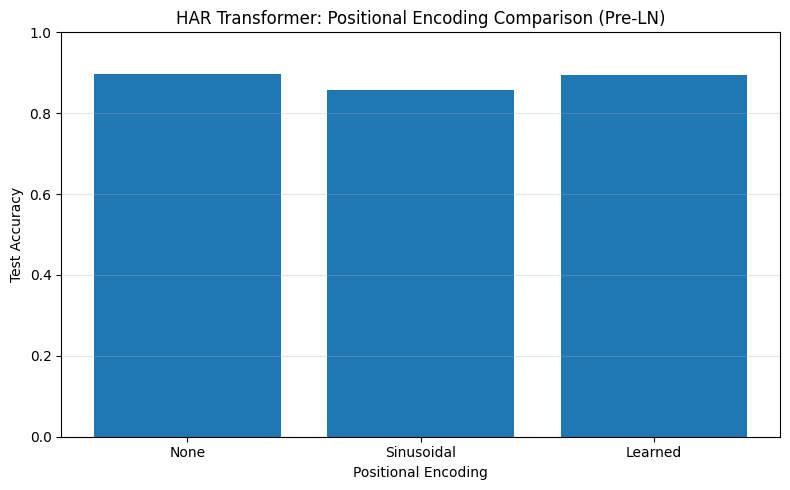

In [118]:

import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(8, 5))

plt.bar(
    har_transformer_results["Positional_Encoding"],
    har_transformer_results["Test_Accuracy"]
)

plt.xlabel("Positional Encoding")
plt.ylabel("Test Accuracy")
plt.title("HAR Transformer: Positional Encoding Comparison (Pre-LN)")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR/"har_positional_encoding_comparison_preln.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [120]:
import pandas as pd
import matplotlib.pyplot as plt

# Compare the best Problem 1 model with the Problem 2 Transformer
comparison_data = {
    "Model": [
        "GRU (Problem 1)",
        "Transformer (Problem 2)"
    ],
    "Test Accuracy (%)": [
        88.79,
        89.75
    ],
    "Parameters": [
        14790,
        398982
    ],
    "Seconds Per Epoch": [
        7.7516,
        1.4345
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("PROBLEM 1 vs PROBLEM 2 COMPARISON")
display(comparison_df)

PROBLEM 1 vs PROBLEM 2 COMPARISON


,Model,Test Accuracy (%),Parameters,Seconds Per Epoch
0,GRU (Problem 1),88.79,14790,7.7516
1,Transformer (Problem 2),89.75,398982,1.4345


### Comparison of GRU and Transformer on HAR

The Transformer achieved a test accuracy of 89.75%, slightly higher than the GRU's 88.79%. However, the Transformer has substantially more trainable parameters (398,982 compared with 14,790).

The measured training time per epoch was lower for the Transformer (1.4345 seconds) than for the GRU (7.7516 seconds) in our experiments. This suggests that the Transformer was faster per epoch in this particular setup, despite its larger parameter count.

Overall, the Transformer provided a small improvement in classification accuracy at the cost of a much larger model. The GRU remains more parameter-efficient, which can be useful in memory-constrained environments.

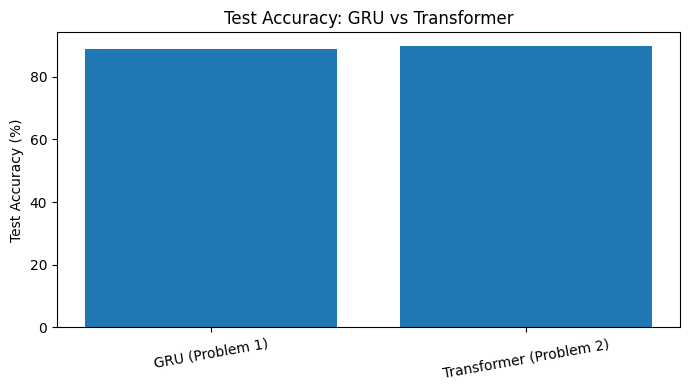

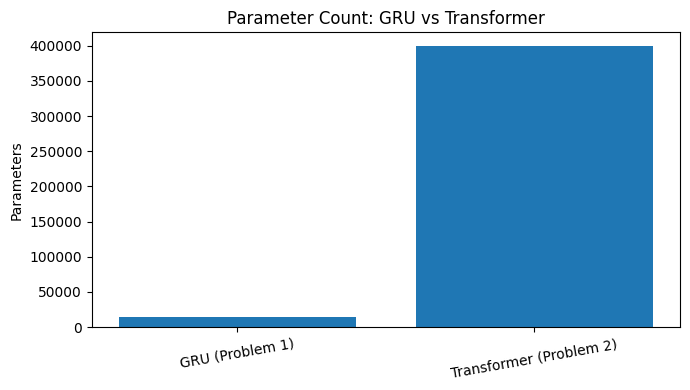

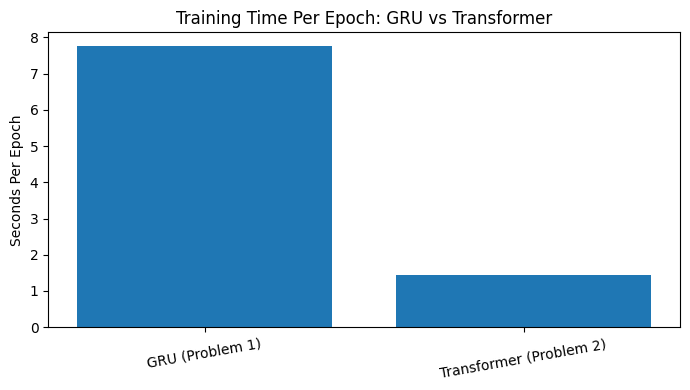

In [121]:
import matplotlib.pyplot as plt

metrics = [
    ("Test Accuracy (%)", "Test Accuracy: GRU vs Transformer"),
    ("Parameters", "Parameter Count: GRU vs Transformer"),
    ("Seconds Per Epoch", "Training Time Per Epoch: GRU vs Transformer")
]

for column, title in metrics:
    plt.figure(figsize=(7, 4))
    plt.bar(comparison_df["Model"], comparison_df[column])
    plt.title(title)
    plt.ylabel(column)
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()


###  Parameter Count Derivation

For a Transformer encoder block, the trainable weight count is:

1. Query, Key, Value and Output projections:
   4d²

2. Feed-forward network:
   2d × d_ff

Therefore:

Total weights = 4d² + 2d × d_ff

For d = 128 and d_ff = 512:

Total weights = 4(128²) + 2(128 × 512)

              = 65,536 + 131,072

              = 196,608

This calculation excludes biases and LayerNorm parameters.


In [119]:

# Count actual parameters in one encoder block

encoder_params = sum(
    p.numel() for p in encoder.parameters()
    if p.requires_grad
)

d_model = 128
d_ff = 512

# Theoretical weight count
theoretical_weights = (
    4 * d_model**2 +
    2 * d_model * d_ff
)

print("Theoretical weights:", theoretical_weights)
print("Actual trainable parameters:", encoder_params)
print("Additional parameters (biases and LayerNorm):",
      encoder_params - theoretical_weights)


Theoretical weights: 196608
Actual trainable parameters: 198272
Additional parameters (biases and LayerNorm): 1664


In [58]:
# Relative path started cell
import os

# Create folders using relative paths
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("generated_samples", exist_ok=True)

print("Output folders created!")

for folder in ["results", "figures", "models", "generated_samples"]:
    print(folder)

Output folders created!
results
figures
models
generated_samples


In [12]:
from pathlib import Path
import pandas as pd

# Create relative output folder
BASE_DIR = Path("Problem2_Results")
BASE_DIR.mkdir(parents=True, exist_ok=True)

# Load the recovered HAR Transformer results
SOURCE_FILE = Path(
    "/kaggle/input/notebooks/samriddhimehta/problem2/har_transformer_results.csv"
)

har_transformer_results = pd.read_csv(SOURCE_FILE)

# Save using a relative path
OUTPUT_FILE = BASE_DIR / "har_transformer_results.csv"

har_transformer_results.to_csv(
    OUTPUT_FILE,
    index=False
)

print("HAR Transformer results restored successfully!")
print("Rows:", len(har_transformer_results))
print("Columns:", list(har_transformer_results.columns))
print(har_transformer_results)
print("Saved to:", OUTPUT_FILE)

HAR Transformer results restored successfully!
Rows: 3
Columns: ['Positional_Encoding', 'Test_Accuracy', 'Macro_F1', 'Parameters', 'Best_Validation_Loss', 'Seconds_Per_Epoch']
  Positional_Encoding  Test_Accuracy  Macro_F1  Parameters  \
0                none       0.886664  0.884918      398982   
1          sinusoidal       0.885307  0.884514      398982   
2             learned       0.876824  0.874533      415494   

   Best_Validation_Loss  Seconds_Per_Epoch  
0              0.423680           1.441926  
1              0.427214           1.465360  
2              0.426705           1.484128  
Saved to: Problem2_Results/har_transformer_results.csv


In [13]:
assert "har_transformer_results" in globals()
assert len(har_transformer_results) == 3
assert OUTPUT_FILE.exists()

check_df = pd.read_csv(OUTPUT_FILE)

assert len(check_df) == 3

print("All checks passed!")
print("CSV exists:", OUTPUT_FILE.exists())
print("Recovered rows:", len(check_df))

All checks passed!
CSV exists: True
Recovered rows: 3


In [14]:
# Save the positional encoding comparison results

har_transformer_results.to_csv(
    BASE_DIR / "har_transformer_results.csv",
    index=False
)

print("HAR results saved successfully!")
print(har_transformer_results)

HAR results saved successfully!
  Positional_Encoding  Test_Accuracy  Macro_F1  Parameters  \
0                none       0.886664  0.884918      398982   
1          sinusoidal       0.885307  0.884514      398982   
2             learned       0.876824  0.874533      415494   

   Best_Validation_Loss  Seconds_Per_Epoch  
0              0.423680           1.441926  
1              0.427214           1.465360  
2              0.426705           1.484128  


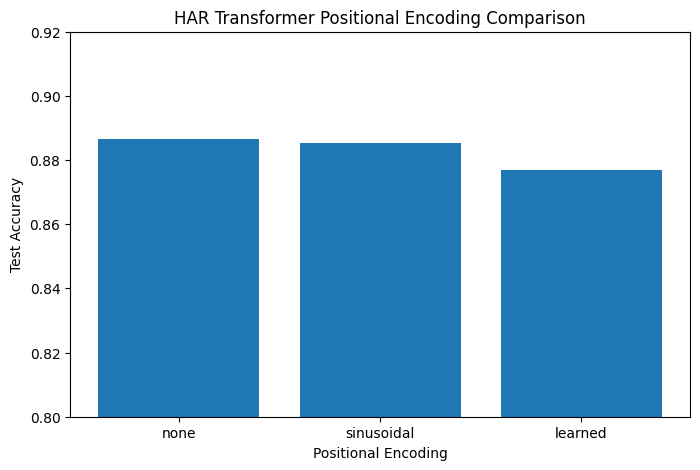

Figure saved!


In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    har_transformer_results["Positional_Encoding"],
    har_transformer_results["Test_Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.xlabel("Positional Encoding")
plt.title("HAR Transformer Positional Encoding Comparison")
plt.ylim(0.80, 0.92)

plt.savefig(
    FIGURES_DIR/"har_positional_encoding_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved!")

In [61]:
import shutil

shutil.make_archive(
    "Problem2_Results_Backup",
    "zip",
    ".",
    base_dir="results"
)

print("Results backup created!")

Results backup created!


In [15]:
# Verify Problem 2 output folders

print("Results folder:", BASE_DIR.exists())
print("Figures folder:", FIGURES_DIR.exists())

print("\nSaved CSV files:")
for file in BASE_DIR.glob("*.csv"):
    print(file)

print("\nSaved figures:")
for file in FIGURES_DIR.glob("*.png"):
    print(file)

print(
    "\nBackup exists:",
    Path("Problem2_Results_Backup.zip").exists()
)

Results folder: True
Figures folder: True

Saved CSV files:
Problem2_Results/har_transformer_results.csv

Saved figures:

Backup exists: False


### 3.4 Comparison with the Best Problem 1 Model

The best recurrent model from Problem 1 was the GRU, which achieved a mean test accuracy of 88.79% across three random seeds.

The best HAR Transformer configuration was the model without positional encoding, which achieved a test accuracy of 88.67%.

The two models are compared in terms of test accuracy, parameter count and average training time per epoch.

In [66]:
import pandas as pd

comparison_data = {
    "Model": ["GRU (Problem 1)", "Transformer (Problem 2)"],
    "Test Accuracy (%)": [88.79, 88.67],
    "Parameters": [14790, 398982],
    "Seconds Per Epoch": [7.7516, 1.44]
}

comparison_df = pd.DataFrame(comparison_data)

print(comparison_df.to_string(index=False))

                  Model  Test Accuracy (%)  Parameters  Seconds Per Epoch
        GRU (Problem 1)              88.79       14790             7.7516
Transformer (Problem 2)              88.67      398982             1.4400


**Analysis:**

The GRU achieved a slightly higher test accuracy of 88.79%, compared with 88.67% for the Transformer.

However, the Transformer contains significantly more parameters (398,982 compared with 14,790 for the GRU). The Transformer also had a lower recorded average time per epoch.

This comparison shows that the GRU provides a much smaller model with comparable classification accuracy, while the Transformer offers a different attention-based architecture with higher parameter requirements.

**Comparison and Observations:**

The GRU achieved a test accuracy of 88.79%, while the Transformer achieved 88.67%. Both models demonstrate comparable performance on the HAR classification task.

The GRU has 14,790 parameters, whereas the Transformer has 398,982 parameters. This indicates that the GRU is considerably more parameter-efficient for this task.

The results highlight the trade-off between model complexity, classification accuracy and computational time.

## Task 4: Character-Level Causal Language Model

### 4.1 Dataset Preparation – Tiny Shakespeare

In this task, we implement a character-level causal language model using the Tiny Shakespeare dataset. The model learns patterns in Shakespeare's text by predicting the next character based on previously observed characters.

In [68]:
import os
import urllib.request

# Create data folder
os.makedirs("data", exist_ok=True)

# Download Tiny Shakespeare dataset
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

file_path = "data/tinyshakespeare.txt"

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)

# Read dataset
with open(file_path, "r", encoding="utf-8") as f:
    text_data = f.read()

# Display dataset information
print("Dataset downloaded successfully!")
print("Total characters:", len(text_data))
print("Unique characters:", len(set(text_data)))

print("\nFirst 500 characters:\n")
print(text_data[:500])

Dataset downloaded successfully!
Total characters: 1115394
Unique characters: 65

First 500 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


### 4.2 Character Vocabulary and Train-Validation Split

A character-level language model works with individual characters instead of words.

We create a vocabulary of all unique characters and assign each character a unique integer ID. The encoded dataset is then divided into training and validation sets using a 90:10 split.

In [69]:
import torch

# Create sorted character vocabulary
chars = sorted(list(set(text_data)))

vocab_size = len(chars)

# Create character-to-integer mapping
stoi = {ch: i for i, ch in enumerate(chars)}

# Create integer-to-character mapping
itos = {i: ch for i, ch in enumerate(chars)}

# Encoding function
def encode(s):
    return [stoi[c] for c in s]

# Decoding function
def decode(indices):
    return ''.join([itos[i] for i in indices])

# Convert complete text into integer IDs
data = torch.tensor(encode(text_data), dtype=torch.long)

# Split dataset: 90% training, 10% validation
split_index = int(0.9 * len(data))

train_data = data[:split_index]
val_data = data[split_index:]

print("Vocabulary size:", vocab_size)
print("Total encoded characters:", len(data))
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

# Verify encoding and decoding
sample = text_data[:20]

print("\nOriginal text:", repr(sample))
print("Encoded text:", encode(sample))
print("Decoded text:", decode(encode(sample)))

Vocabulary size: 65
Total encoded characters: 1115394
Training characters: 1003854
Validation characters: 111540

Original text: 'First Citizen:\nBefor'
Encoded text: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]
Decoded text: First Citizen:
Befor


### 4.3 Context Window and Batch Generation

The language model uses a fixed context window of 128 characters to predict the next character.

We create batches of input sequences and their corresponding target sequences. Each target sequence is shifted one position to the right, allowing the model to learn next-character prediction.

In [70]:
# Transformer configuration
block_size = 128
batch_size = 64

# Function to generate a batch of training or validation data
def get_batch(split):
    source = train_data if split == "train" else val_data

    # Random starting positions
    ix = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    # Input sequences
    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    # Target sequences (shifted by one character)
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    return x, y


# Test batch generation
xb, yb = get_batch("train")

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)

print("\nFirst input sequence:")
print(decode(xb[0].tolist()))

print("\nCorresponding target sequence:")
print(decode(yb[0].tolist()))

Input batch shape: torch.Size([64, 128])
Target batch shape: torch.Size([64, 128])

First input sequence:
ive years
I never spake with her, saw her, nor heard from her,
Upon my faith and honour.

MARIANA:
Noble prince,
As there comes 

Corresponding target sequence:
ve years
I never spake with her, saw her, nor heard from her,
Upon my faith and honour.

MARIANA:
Noble prince,
As there comes l


### 4.4 Transformer Language Model Architecture

We implement a character-level Transformer language model using the custom multi-head attention and encoder components developed earlier.

The model uses:
- Vocabulary size: 65
- Embedding dimension: 128
- Number of attention heads: 4
- Number of Transformer layers: 4
- Context length: 128

Unlike the HAR encoder classifier, this model uses causal self-attention so that each character can attend only to itself and previous characters.

In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model=128, num_heads=4, dropout=0.1):
        super().__init__()

        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        q = self.W_Q(x)
        k = self.W_K(x)
        v = self.W_V(x)

        # Split into attention heads
        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        # Causal self-attention
        output = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True,
            dropout_p=self.dropout.p if self.training else 0.0
        )

        # Combine attention heads
        output = output.transpose(1, 2).contiguous().view(B, T, C)

        return self.W_O(output)

### 4.5 Pre-LayerNorm Transformer Block

Each Transformer block consists of two main sublayers:

1. Causal multi-head self-attention.
2. A feed-forward neural network with hidden dimension 4 times the embedding dimension.

We use pre-LayerNorm, residual connections and dropout to improve training stability.

In [72]:
class CausalTransformerBlock(nn.Module):
    def __init__(self, d_model=128, num_heads=4, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        self.ln2 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        # Attention with residual connection
        x = x + self.dropout(self.attention(self.ln1(x)))

        # Feed-forward network with residual connection
        x = x + self.feed_forward(self.ln2(x))

        return x

### 4.6 Complete Transformer Language Model

The complete language model contains character embeddings, positional embeddings, four causal Transformer blocks, final LayerNorm and a linear output layer.

The output layer predicts a probability distribution over the 65-character vocabulary for every position in the input sequence.

In [73]:
class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=128,
        num_heads=4,
        num_layers=4,
        block_size=128,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        # Character and positional embeddings
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(block_size, d_model)

        # Four Transformer blocks
        self.blocks = nn.Sequential(
            *[
                CausalTransformerBlock(
                    d_model=d_model,
                    num_heads=num_heads,
                    dropout=dropout
                )
                for _ in range(num_layers)
            ]
        )

        self.final_norm = nn.LayerNorm(d_model)

        # Predict the next character
        self.language_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):

        B, T = idx.shape

        token_embeddings = self.token_embedding(idx)

        positions = torch.arange(T, device=idx.device)
        position_embeddings = self.position_embedding(positions)

        x = token_embeddings + position_embeddings

        x = self.blocks(x)
        x = self.final_norm(x)

        logits = self.language_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            logits = logits.view(B * T, C)
            targets = targets.view(B * T)

            loss = F.cross_entropy(logits, targets)

        return logits, loss

### 4.7 Model Initialization and Architecture Verification

We initialize the Transformer language model using the required configuration and verify its output dimensions and total trainable parameters.

In [74]:
# Set model configuration
d_model = 128
num_heads = 4
num_layers = 4
block_size = 128
dropout = 0.1

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize model
model = TransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    block_size=block_size,
    dropout=dropout
).to(device)

# Test with one batch
xb, yb = get_batch("train")

xb = xb.to(device)
yb = yb.to(device)

logits, loss = model(xb, yb)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())
print("Total trainable parameters:", total_params)
print("Number of Transformer layers:", num_layers)
print("Embedding dimension:", d_model)
print("Attention heads:", num_heads)
print("Context length:", block_size)

Device: cuda
Logits shape: torch.Size([8192, 65])
Initial loss: 4.3817572593688965
Total trainable parameters: 826433
Number of Transformer layers: 4
Embedding dimension: 128
Attention heads: 4
Context length: 128


### 4.8 Training and Validation

We train the character-level Transformer using cross-entropy loss and the AdamW optimizer.

The model learns to predict the next character from the previous 128 characters. We evaluate both training and validation loss periodically to monitor learning and detect overfitting.

We also record the training and validation losses to plot the learning curves.

In [75]:
import time
import matplotlib.pyplot as plt
import numpy as np

# Training configuration
learning_rate = 3e-4
max_iters = 5000
eval_interval = 500
eval_iters = 50

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

@torch.no_grad()
def estimate_loss():
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):
            X, Y = get_batch(split)

            X = X.to(device)
            Y = Y.to(device)

            _, loss = model(X, Y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()
    return results

In [76]:
train_losses = []
val_losses = []
training_times = []

start_time = time.time()

model.train()

for iteration in range(max_iters):

    # Evaluate periodically
    if iteration % eval_interval == 0:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        elapsed = time.time() - start_time
        training_times.append(elapsed)

        print(
            f"Iteration {iteration}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Validation Loss {losses['val']:.4f}, "
            f"Time {elapsed:.2f}s"
        )

    # Get training batch
    xb, yb = get_batch("train")

    xb = xb.to(device)
    yb = yb.to(device)

    # Forward pass
    logits, loss = model(xb, yb)

    # Backpropagation
    optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Update model parameters
    optimizer.step()

# Final evaluation
final_losses = estimate_loss()

total_training_time = time.time() - start_time

print("\nTraining completed!")
print("Final training loss:", final_losses["train"])
print("Final validation loss:", final_losses["val"])
print("Total training time:", round(total_training_time, 2), "seconds")

Iteration 0: Train Loss 4.3872, Validation Loss 4.3792, Time 0.96s
Iteration 500: Train Loss 2.3091, Validation Loss 2.3230, Time 14.21s
Iteration 1000: Train Loss 1.9989, Validation Loss 2.0638, Time 27.81s
Iteration 1500: Train Loss 1.8054, Validation Loss 1.9229, Time 41.73s
Iteration 2000: Train Loss 1.6881, Validation Loss 1.8379, Time 55.68s
Iteration 2500: Train Loss 1.6028, Validation Loss 1.7764, Time 69.40s
Iteration 3000: Train Loss 1.5563, Validation Loss 1.7324, Time 82.95s
Iteration 3500: Train Loss 1.5121, Validation Loss 1.6903, Time 96.49s
Iteration 4000: Train Loss 1.4820, Validation Loss 1.6634, Time 110.07s
Iteration 4500: Train Loss 1.4489, Validation Loss 1.6288, Time 123.72s

Training completed!
Final training loss: 1.4260718822479248
Final validation loss: 1.6090348958969116
Total training time: 137.41 seconds


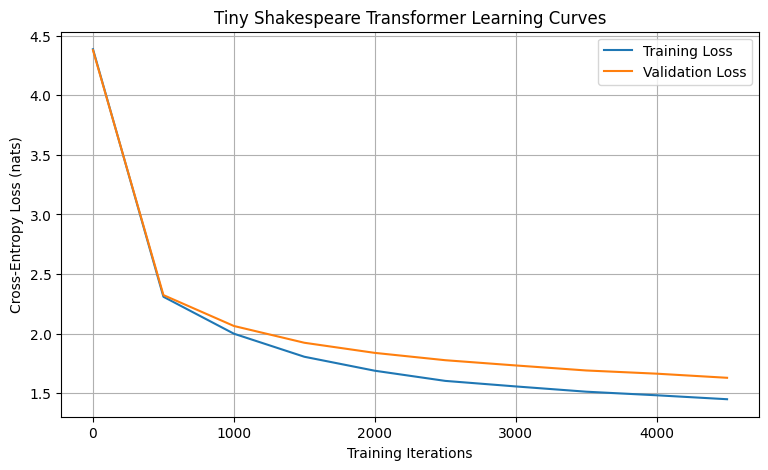

In [77]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(0, max_iters, eval_interval),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(0, max_iters, eval_interval),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Training Iterations")
plt.ylabel("Cross-Entropy Loss (nats)")
plt.title("Tiny Shakespeare Transformer Learning Curves")
plt.legend()
plt.grid(True)

os.makedirs("figures", exist_ok=True)

plt.savefig(
    FIGURES_DIR/"tiny_shakespeare_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
import math

validation_loss = final_losses["val"]

bits_per_character = validation_loss / math.log(2)

print("Final Validation Loss (nats):", round(validation_loss, 4))
print("Bits per Character:", round(bits_per_character, 4))

Final Validation Loss (nats): 1.609
Bits per Character: 2.3213


### 4.9 Text Generation Using Temperature and Top-k Sampling

After training, we use the model to generate new text character by character.

Temperature controls the randomness of predictions:
- Low temperature (0.2): produces more predictable and repetitive text.
- Medium temperature (0.8): balances coherence and creativity.
- High temperature (1.5): produces more diverse and unpredictable text.

Top-k sampling restricts the next-character selection to the k most likely characters.

### 4.9.1 Text Generation Func

In [82]:
@torch.no_grad()
def generate_text(model, start_text, max_new_tokens=500,
                  temperature=1.0, top_k=20):

    model.eval()

    context = torch.tensor(
        [encode(start_text)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):

        context_crop = context[:, -block_size:]

        logits, _ = model(context_crop)

        logits = logits[:, -1, :]

        logits = logits / temperature

        values, indices = torch.topk(logits, top_k)

        filtered_logits = torch.full_like(logits, float("-inf"))
        filtered_logits.scatter_(1, indices, values)

        probabilities = F.softmax(filtered_logits, dim=-1)

        next_char = torch.multinomial(probabilities, num_samples=1)

        context = torch.cat((context, next_char), dim=1)

    model.train()

    return decode(context[0].tolist())

In [83]:
# Use a different Shakespeare character as the starting prompt
start_text = "KING LEAR:\n"

# Generate 500 new characters at each temperature
generated_02 = generate_text(
    model,
    start_text,
    max_new_tokens=500,
    temperature=0.2,
    top_k=20
)

generated_08 = generate_text(
    model,
    start_text,
    max_new_tokens=500,
    temperature=0.8,
    top_k=20
)

generated_15 = generate_text(
    model,
    start_text,
    max_new_tokens=500,
    temperature=1.5,
    top_k=20
)

print("=" * 60)
print("TEMPERATURE 0.2 – LOW RANDOMNESS")
print("=" * 60)
print(generated_02)

print("\n" + "=" * 60)
print("TEMPERATURE 0.8 – MODERATE RANDOMNESS")
print("=" * 60)
print(generated_08)

print("\n" + "=" * 60)
print("TEMPERATURE 1.5 – HIGH RANDOMNESS")
print("=" * 60)
print(generated_15)

TEMPERATURE 0.2 – LOW RANDOMNESS
KING LEAR:
What was the sent the man sound the sight of the man the father
And stand the shall be prince of the sea
That with the prove of the world that shall be some
The shall be so of your father soul prince to thee,
That I have have shall be my lord,
And he hath the shall be so so so her shall be the sea
the stand of the people of my lord,
And the shall be so so so much a such and man
That he shall be my lord, and so man the death,
And the shall be so so more of the seasons of the sea
of the shall not 

TEMPERATURE 0.8 – MODERATE RANDOMNESS
KING LEAR:
God!

AUNE:
The full.

LADY GREY:
O, your come? shall have shall I sake on him day.

KING RICHARD III:
Speak my pause.

MONTAGUE:

Nurse:
Nay, you would a morther!

LUCIO:
Come, here far his too merry intent.

MENENIUS:
I am all seem, live please upon them friends,
What you, I know from me; 'tis may contends,
I'll not do the say our gracious in man,
And his defect me me as her wind his heart:
That she 

### 4.10 Saving Generated Text Samples

The model generates 500 characters at three different temperature values using top-k sampling. We save the generated samples for further analysis and comparison.

In [84]:
import os

os.makedirs("generated_samples", exist_ok=True)

# Save generated samples
samples = {
    "temperature_0.2.txt": generated_02,
    "temperature_0.8.txt": generated_08,
    "temperature_1.5.txt": generated_15
}

for filename, generated_text in samples.items():

    with open(
        os.path.join("generated_samples", filename),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(generated_text)

    print(filename, ":", len(generated_text), "characters")

print("\nAll generated samples saved successfully!")

temperature_0.2.txt : 511 characters
temperature_0.8.txt : 511 characters
temperature_1.5.txt : 511 characters

All generated samples saved successfully!


### 4.11 Temperature Comparison and Observations

Temperature controls the randomness of character generation.

- Temperature 0.2: Lower temperature produces more predictable character choices and may result in repetitive text.
- Temperature 0.8: Moderate temperature provides a balance between predictable patterns and variation.
- Temperature 1.5: Higher temperature increases randomness and may produce less coherent text.

Top-k sampling restricts the next-character prediction to the 20 most probable characters.

The generated samples are compared to understand how temperature affects text diversity, repetition and coherence.

### 5.1 Attention Heatmaps of Two Attention Heads

We visualize the attention weights of two heads from the first Transformer block using a sample Shakespeare sentence.

The heatmaps illustrate how each character attends to previous characters and itself while predicting the next character. Since causal masking is applied, attention to future positions is not allowed.

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import math

# Select a sentence from Tiny Shakespeare
sentence = "First Citizen:\nBefore we proceed any further, hear me speak."

# Encode sentence
sentence_ids = encode(sentence)

x = torch.tensor(
    [sentence_ids],
    dtype=torch.long,
    device=device
)

model.eval()

with torch.no_grad():

    # Token and positional embeddings
    B, T = x.shape

    positions = torch.arange(T, device=device)

    embeddings = (
        model.token_embedding(x)
        + model.position_embedding(positions)
    )

    # Get first Transformer block
    block = model.blocks[0]
    attention = block.attention

    # Apply the first LayerNorm
    normalized_x = block.ln1(embeddings)

    # Calculate Q and K
    q = attention.W_Q(normalized_x)
    k = attention.W_K(normalized_x)

    # Reshape into attention heads
    q = q.view(
        B, T, attention.num_heads, attention.head_dim
    ).transpose(1, 2)

    k = k.view(
        B, T, attention.num_heads, attention.head_dim
    ).transpose(1, 2)

    # Calculate scaled attention scores
    scores = torch.matmul(
        q, k.transpose(-2, -1)
    ) / math.sqrt(attention.head_dim)

    # Apply causal mask
    causal_mask = torch.triu(
        torch.ones(T, T, device=device, dtype=torch.bool),
        diagonal=1
    )

    scores = scores.masked_fill(causal_mask, float("-inf"))

    # Convert scores into attention weights
    attention_weights = torch.softmax(scores, dim=-1)

    # Extract first two heads
    head1_weights = attention_weights[0, 0].cpu().numpy()
    head2_weights = attention_weights[0, 1].cpu().numpy()

print("Sentence:", repr(sentence))
print("Attention matrix shape:", head1_weights.shape)
print("Future attention weights:", 
      attention_weights[0, 0].masked_select(causal_mask).sum().item())

Sentence: 'First Citizen:\nBefore we proceed any further, hear me speak.'
Attention matrix shape: (60, 60)
Future attention weights: 0.0


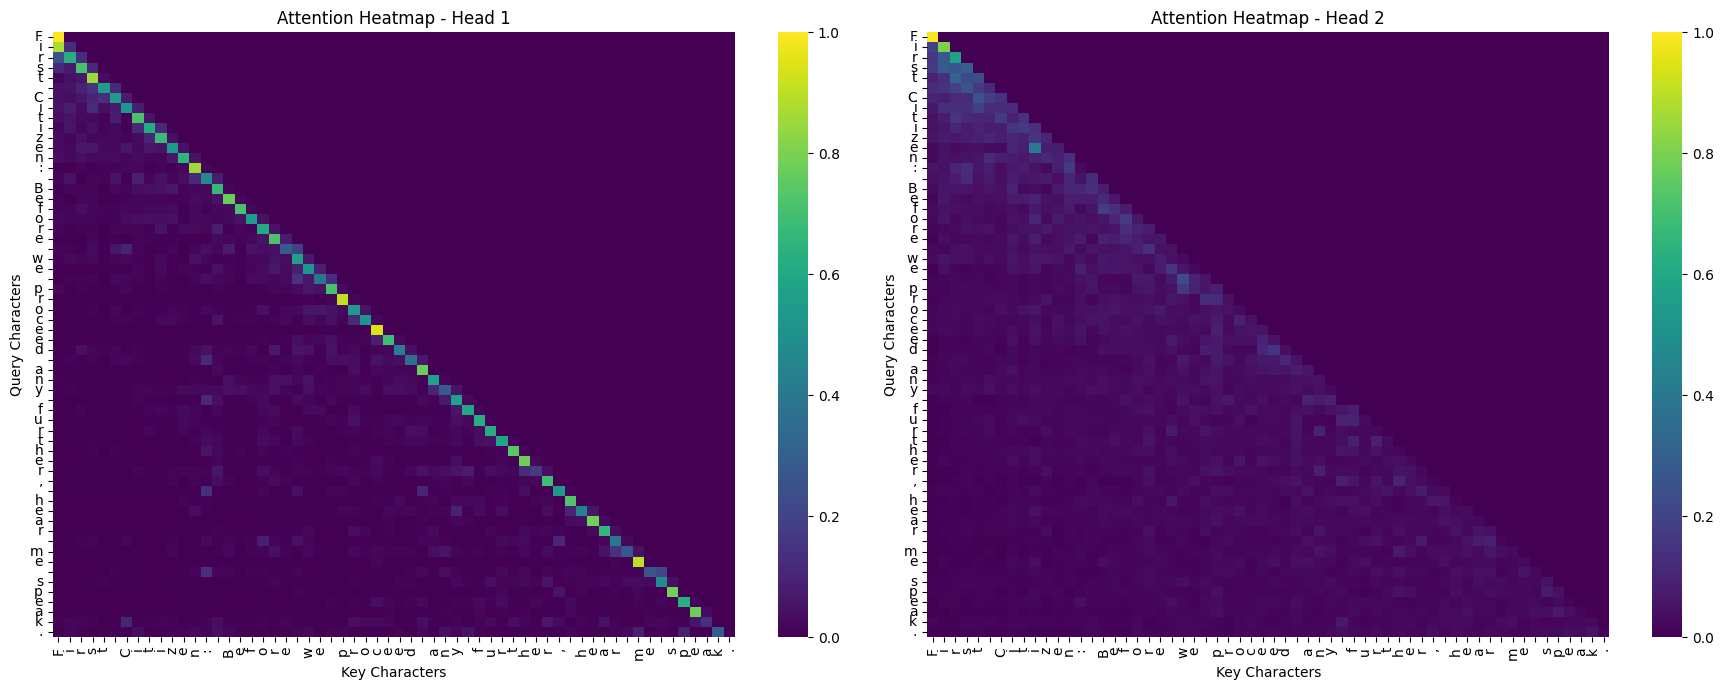

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

character_labels = list(sentence)

sns.heatmap(
    head1_weights,
    ax=axes[0],
    cmap="viridis",
    xticklabels=character_labels,
    yticklabels=character_labels
)

axes[0].set_title("Attention Heatmap - Head 1")
axes[0].set_xlabel("Key Characters")
axes[0].set_ylabel("Query Characters")

sns.heatmap(
    head2_weights,
    ax=axes[1],
    cmap="viridis",
    xticklabels=character_labels,
    yticklabels=character_labels
)

axes[1].set_title("Attention Heatmap - Head 2")
axes[1].set_xlabel("Key Characters")
axes[1].set_ylabel("Query Characters")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)

plt.savefig(
    FIGURES_DIR/"attention_heatmaps_two_heads.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations:**

The attention heatmaps show different attention patterns for the two selected heads.

Head 1 exhibits strong diagonal attention, indicating that many positions assign high importance to their own character representations. Some additional attention is assigned to selected earlier positions.

Head 2 displays a more distributed attention pattern across previous characters, suggesting that it captures a broader context.

Both heads follow causal masking, as confirmed by the zero attention weights for future positions. Therefore, the model cannot access future characters while predicting the next character.

### 5.2 Effect of Number of Attention Heads

In this experiment, we investigate how the number of attention heads affects the performance of the character-level Transformer language model.

We compare three configurations with 1, 4 and 8 attention heads while keeping the embedding dimension fixed at 128.

All configurations use the same dataset, context length, number of Transformer layers and training settings. We compare validation loss, parameter count and training time.

In [87]:
import time
import random
import numpy as np
import pandas as pd

def train_head_ablation(num_heads, max_iters=1500):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    # Create a fresh model
    ablation_model = TransformerLanguageModel(
        vocab_size=vocab_size,
        d_model=128,
        num_heads=num_heads,
        num_layers=4,
        block_size=128,
        dropout=0.1
    ).to(device)

    optimizer = torch.optim.AdamW(
        ablation_model.parameters(),
        lr=3e-4
    )

    start_time = time.time()

    ablation_model.train()

    for iteration in range(max_iters):

        xb, yb = get_batch("train")
        xb = xb.to(device)
        yb = yb.to(device)

        _, loss = ablation_model(xb, yb)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    training_time = time.time() - start_time

    # Evaluate validation loss
    ablation_model.eval()

    validation_losses = []

    with torch.no_grad():
        for _ in range(50):
            xb, yb = get_batch("val")
            xb = xb.to(device)
            yb = yb.to(device)

            _, val_loss = ablation_model(xb, yb)
            validation_losses.append(val_loss.item())

    validation_loss = np.mean(validation_losses)

    parameters = sum(
        p.numel() for p in ablation_model.parameters()
        if p.requires_grad
    )

    return {
        "Attention_Heads": num_heads,
        "Validation_Loss": validation_loss,
        "Parameters": parameters,
        "Training_Time_Seconds": training_time
    }

In [88]:
head_results = []

for heads in [1, 4, 8]:

    print(f"\nTraining model with {heads} attention head(s)...")

    result = train_head_ablation(
        num_heads=heads,
        max_iters=1500
    )

    head_results.append(result)

    print(result)

head_ablation_df = pd.DataFrame(head_results)

print("\nAttention Head Ablation Results:")
print(head_ablation_df.to_string(index=False))


Training model with 1 attention head(s)...
{'Attention_Heads': 1, 'Validation_Loss': np.float64(1.8940687727928163), 'Parameters': 826433, 'Training_Time_Seconds': 35.50378131866455}

Training model with 4 attention head(s)...
{'Attention_Heads': 4, 'Validation_Loss': np.float64(1.915033345222473), 'Parameters': 826433, 'Training_Time_Seconds': 38.583271741867065}

Training model with 8 attention head(s)...
{'Attention_Heads': 8, 'Validation_Loss': np.float64(1.957351746559143), 'Parameters': 826433, 'Training_Time_Seconds': 42.11814522743225}

Attention Head Ablation Results:
 Attention_Heads  Validation_Loss  Parameters  Training_Time_Seconds
               1         1.894069      826433              35.503781
               4         1.915033      826433              38.583272
               8         1.957352      826433              42.118145


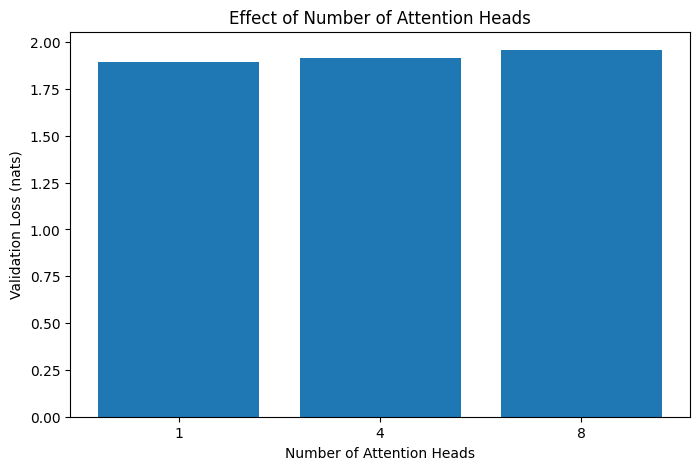

In [89]:
plt.figure(figsize=(8, 5))

plt.bar(
    head_ablation_df["Attention_Heads"].astype(str),
    head_ablation_df["Validation_Loss"]
)

plt.xlabel("Number of Attention Heads")
plt.ylabel("Validation Loss (nats)")
plt.title("Effect of Number of Attention Heads")

plt.savefig(
    FIGURES_DIR/"attention_heads_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.3 Effect of Removing the Causal Mask

In this experiment, we investigate the importance of causal masking in an autoregressive language model.

We compare the standard causal Transformer with a Transformer that uses unrestricted self-attention.

Without causal masking, each position can access future characters. This introduces information leakage during training because the model can use information that should not be available when predicting the next character.

We compare training loss, validation loss and generated text to understand the effect of removing the causal mask.


In [90]:
class UnmaskedSelfAttention(CausalSelfAttention):

    def forward(self, x):
        B, T, C = x.shape

        q = self.W_Q(x)
        k = self.W_K(x)
        v = self.W_V(x)

        q = q.view(
            B, T, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, T, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, T, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # No causal mask: all positions can attend to all positions
        output = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=False,
            dropout_p=self.dropout.p if self.training else 0.0
        )

        output = output.transpose(1, 2).contiguous().view(B, T, C)

        return self.W_O(output)

In [91]:
class UnmaskedTransformerBlock(CausalTransformerBlock):

    def __init__(self, d_model=128, num_heads=4, dropout=0.1):
        super().__init__(d_model, num_heads, dropout)

        self.attention = UnmaskedSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

In [92]:
class UnmaskedTransformerLanguageModel(TransformerLanguageModel):

    def __init__(self, vocab_size, d_model=128, num_heads=4,
                 num_layers=4, block_size=128, dropout=0.1):

        super().__init__(
            vocab_size=vocab_size,
            d_model=d_model,
            num_heads=num_heads,
            num_layers=num_layers,
            block_size=block_size,
            dropout=dropout
        )

        self.blocks = nn.Sequential(
            *[
                UnmaskedTransformerBlock(
                    d_model=d_model,
                    num_heads=num_heads,
                    dropout=dropout
                )
                for _ in range(num_layers)
            ]
        )

### 5.3.1 Training the Transformer Without Causal Masking

In this experiment, we train a Transformer without causal masking. Unlike the standard causal model, this model can attend to both previous and future positions within the input sequence.

We use the same embedding dimension, number of layers, attention heads, context length, optimizer and training iterations to study the effect of removing the causal mask.

In [93]:
import time
import random
import numpy as np
import pandas as pd

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Initialize a separate unmasked model
unmasked_model = UnmaskedTransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=128,
    num_heads=4,
    num_layers=4,
    block_size=128,
    dropout=0.1
).to(device)

# Optimizer
unmasked_optimizer = torch.optim.AdamW(
    unmasked_model.parameters(),
    lr=3e-4
)

unmasked_train_losses = []

start_time = time.time()

unmasked_model.train()

# Train for 1500 iterations
for iteration in range(1500):

    xb, yb = get_batch("train")

    xb = xb.to(device)
    yb = yb.to(device)

    _, loss = unmasked_model(xb, yb)

    unmasked_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    unmasked_optimizer.step()

    if iteration % 300 == 0:
        unmasked_train_losses.append(loss.item())

        print(
            f"Iteration {iteration}: "
            f"Training Loss = {loss.item():.4f}"
        )

unmasked_training_time = time.time() - start_time

print("\nUnmasked model training completed!")
print("Training time:", round(unmasked_training_time, 2), "seconds")

Iteration 0: Training Loss = 4.3298
Iteration 300: Training Loss = 2.4289
Iteration 600: Training Loss = 0.0776
Iteration 900: Training Loss = 0.0350
Iteration 1200: Training Loss = 0.0256

Unmasked model training completed!
Training time: 40.95 seconds


In [94]:
@torch.no_grad()
def evaluate_language_model(eval_model, split, batches=50):

    eval_model.eval()
    losses = []

    for _ in range(batches):
        xb, yb = get_batch(split)

        xb = xb.to(device)
        yb = yb.to(device)

        _, loss = eval_model(xb, yb)
        losses.append(loss.item())

    return float(np.mean(losses))


# Evaluate original causal model
causal_train_loss = evaluate_language_model(
    model, "train"
)

causal_val_loss = evaluate_language_model(
    model, "val"
)

# Evaluate unmasked model
unmasked_train_loss = evaluate_language_model(
    unmasked_model, "train"
)

unmasked_val_loss = evaluate_language_model(
    unmasked_model, "val"
)

# Create comparison table
mask_comparison = pd.DataFrame({
    "Model": ["Causal Transformer", "Unmasked Transformer"],
    "Training Loss": [
        causal_train_loss,
        unmasked_train_loss
    ],
    "Validation Loss": [
        causal_val_loss,
        unmasked_val_loss
    ]
})

print(mask_comparison.to_string(index=False))

               Model  Training Loss  Validation Loss
  Causal Transformer       1.425732         1.613663
Unmasked Transformer       0.021111         0.021162


**Observations:**

The causal Transformer achieved a validation loss of 1.6137 nats, whereas the unmasked Transformer achieved a much lower validation loss of 0.0212 nats.

The unmasked model can access future characters during training and validation. This introduces information leakage, allowing it to predict target characters using information that would not be available during actual text generation.

Therefore, the lower loss of the unmasked model is misleading. Causal masking is essential for valid autoregressive language modelling.

### 5.3.2 Comparison of Causal and Unmasked Transformer Loss

We visualize the training and validation losses of both models to demonstrate the effect of future information leakage when causal masking is removed.

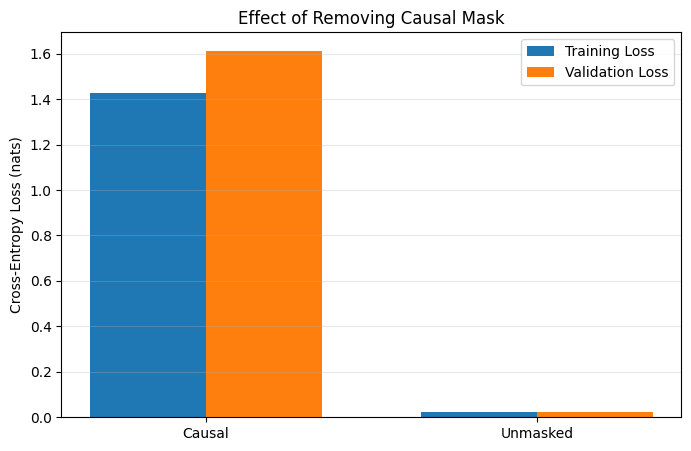

In [95]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Causal", "Unmasked"]

train_values = [
    causal_train_loss,
    unmasked_train_loss
]

val_values = [
    causal_val_loss,
    unmasked_val_loss
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, train_values, width, label="Training Loss")
plt.bar(x + width/2, val_values, width, label="Validation Loss")

plt.xticks(x, labels)
plt.ylabel("Cross-Entropy Loss (nats)")
plt.title("Effect of Removing Causal Mask")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    FIGURES_DIR/"causal_vs_unmasked_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.3.3 Text Generation Comparison

We compare text generated by the causal and unmasked Transformers using the same starting prompt and sampling settings.

This experiment helps demonstrate whether the unmasked model's low validation loss translates into meaningful autoregressive text generation.

In [96]:
# Use the same prompt and sampling settings
start_text = "KING LEAR:\n"

# Generate from the original causal model
causal_sample = generate_text(
    model,
    start_text,
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
)

# Generate from the unmasked model
unmasked_sample = generate_text(
    unmasked_model,
    start_text,
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
)

print("========== CAUSAL TRANSFORMER ==========")
print(causal_sample)

print("\n========== UNMASKED TRANSFORMER ==========")
print(unmasked_sample)

========== CAUSAL TRANSFORMER ==========
KING LEAR:
Henry, my Lady with still, yet in my many too.

ROMEO:
Have not my fool, our with true to-morrow his become,
To make which is on his sleep of all:
But in breason of his we go,
And with heart of children speak with thy grief.
How those pray with our many for of grieve,
And was how may have an inshing

========== UNMASKED TRANSFORMER ==========
KING LEAR:
CLULLUSULUCULECULU ACULULLULULULULUUKCUCULLULLULLUUCULULLULLULUULULLUCULULULULLUUCULLUUCUCULLULUCULLULUULLLULLULULULLULULUUCULULUULULLULULULUULULULULLLULUULULULULULUULUCULULUULULLUULULULUULUULULULUUUULULUUUUUUUUULUUUUUUUUULULUUUUUULUUUUUULUUUULUUUUUUUUUULUUUULUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU


**Observations:**

The causal Transformer generates recognizable Shakespeare-like text with dialogue structure, character names and punctuation.

In contrast, the unmasked Transformer generates highly repetitive character sequences with limited linguistic coherence.

The unmasked model achieves an artificially low validation loss because it can access future characters during training. However, this does not translate into meaningful autoregressive text generation.

This experiment demonstrates why causal masking is essential for next-character prediction.

### 5.4 Effect of Context Length on Training Time and Memory

In this experiment, we investigate how increasing the context length affects the computational cost of the Transformer language model.

We evaluate context lengths of 64, 128, 256 and 512 while keeping the embedding dimension, number of attention heads and number of Transformer layers fixed.

For each configuration, we measure the average forward and backward pass time and peak GPU memory usage.

The experiment helps demonstrate the quadratic computational complexity of self-attention with respect to sequence length, O(n²d).

In [97]:
import time
import gc
import pandas as pd
import torch

def benchmark_context_length(context_length, batch_size=8):

    # Create a fresh model for this context length
    benchmark_model = TransformerLanguageModel(
        vocab_size=vocab_size,
        d_model=128,
        num_heads=4,
        num_layers=4,
        block_size=context_length,
        dropout=0.1
    ).to(device)

    optimizer = torch.optim.AdamW(
        benchmark_model.parameters(),
        lr=3e-4
    )

    # Generate input and target batches
    ix = torch.randint(
        len(train_data) - context_length - 1,
        (batch_size,)
    )

    x = torch.stack([
        train_data[i:i + context_length] for i in ix
    ]).to(device)

    y = torch.stack([
        train_data[i + 1:i + context_length + 1] for i in ix
    ]).to(device)

    benchmark_model.train()

    # Warm-up iterations
    for _ in range(3):
        optimizer.zero_grad(set_to_none=True)
        _, loss = benchmark_model(x, y)
        loss.backward()
        optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)

    # Measure forward + backward + optimizer step
    num_iterations = 10

    start = time.perf_counter()

    for _ in range(num_iterations):
        optimizer.zero_grad(set_to_none=True)

        _, loss = benchmark_model(x, y)

        loss.backward()
        optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    average_time = elapsed / num_iterations

    # Measure peak GPU memory
    if device.type == "cuda":
        peak_memory = (
            torch.cuda.max_memory_allocated(device) / (1024 ** 2)
        )
    else:
        peak_memory = float("nan")

    # Release resources
    del benchmark_model, optimizer, x, y, loss

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "Context_Length": context_length,
        "Average_Step_Time_Seconds": average_time,
        "Peak_GPU_Memory_MB": peak_memory
    }

In [98]:
context_lengths = [64, 128, 256, 512]

context_results = []

for length in context_lengths:

    print(f"\nBenchmarking context length: {length}")

    result = benchmark_context_length(length)

    context_results.append(result)

    print(result)

context_df = pd.DataFrame(context_results)

print("\nContext Length Benchmark Results:")
print(context_df.to_string(index=False))


Benchmarking context length: 64
{'Context_Length': 64, 'Average_Step_Time_Seconds': 0.0084171365999282, 'Peak_GPU_Memory_MB': 142.2431640625}

Benchmarking context length: 128
{'Context_Length': 128, 'Average_Step_Time_Seconds': 0.009046765399943979, 'Peak_GPU_Memory_MB': 161.53515625}

Benchmarking context length: 256
{'Context_Length': 256, 'Average_Step_Time_Seconds': 0.009139891400081979, 'Peak_GPU_Memory_MB': 200.0380859375}

Benchmarking context length: 512
{'Context_Length': 512, 'Average_Step_Time_Seconds': 0.01692593580009998, 'Peak_GPU_Memory_MB': 274.95654296875}

Context Length Benchmark Results:
 Context_Length  Average_Step_Time_Seconds  Peak_GPU_Memory_MB
             64                   0.008417          142.243164
            128                   0.009047          161.535156
            256                   0.009140          200.038086
            512                   0.016926          274.956543


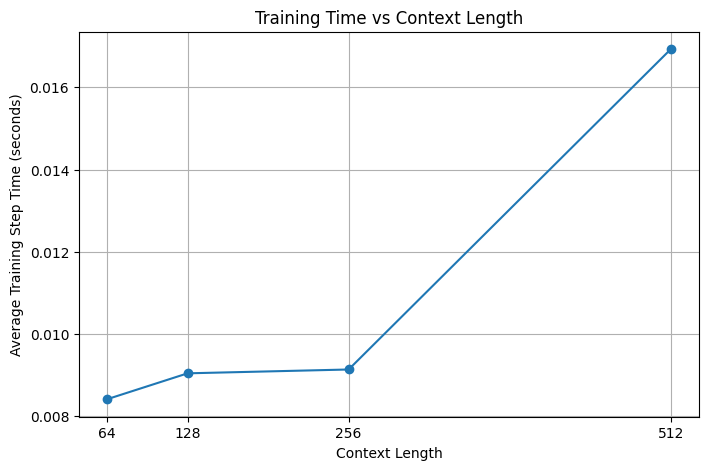

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    context_df["Context_Length"],
    context_df["Average_Step_Time_Seconds"],
    marker="o"
)

plt.xlabel("Context Length")
plt.ylabel("Average Training Step Time (seconds)")
plt.title("Training Time vs Context Length")
plt.xticks([64, 128, 256, 512])
plt.grid(True)

plt.savefig(
    FIGURES_DIR/"context_length_vs_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

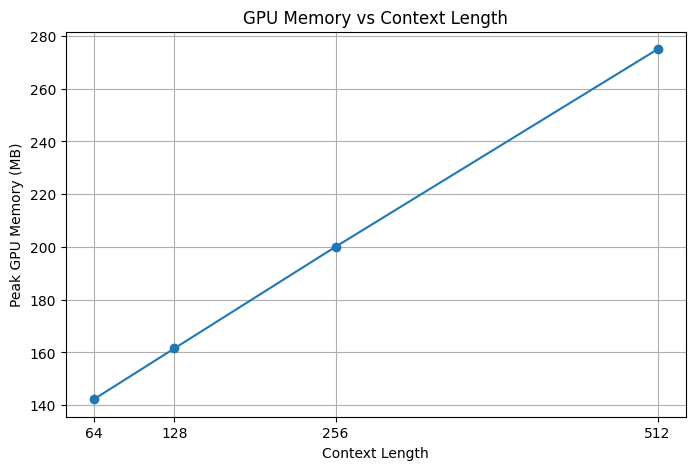

In [100]:
plt.figure(figsize=(8, 5))

plt.plot(
    context_df["Context_Length"],
    context_df["Peak_GPU_Memory_MB"],
    marker="o"
)

plt.xlabel("Context Length")
plt.ylabel("Peak GPU Memory (MB)")
plt.title("GPU Memory vs Context Length")
plt.xticks([64, 128, 256, 512])
plt.grid(True)

plt.savefig(
    FIGURES_DIR/"context_length_vs_gpu_memory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.4.5 Complexity Analysis

Self-attention computes relationships between every pair of positions in a sequence.

For an embedding dimension d and context length n, the attention computation has a complexity of O(n²d).

As the context length increases, the attention matrix grows quadratically. This increases computation time and memory requirements.

The measured results are used to study the relationship between context length, training time and GPU memory consumption.

**Observations:**

GPU memory consumption increases as the context length increases.

The memory usage rises from approximately 142 MB at context length 64 to 275 MB at context length 512.

This happens because longer sequences require larger intermediate tensors and attention computations.

The experiment demonstrates that increasing the context length increases the memory requirements of the Transformer model.

In [101]:
print("CONTEXT LENGTH BENCHMARK SUMMARY")
print(context_df.to_string(index=False))

CONTEXT LENGTH BENCHMARK SUMMARY
 Context_Length  Average_Step_Time_Seconds  Peak_GPU_Memory_MB
             64                   0.008417          142.243164
            128                   0.009047          161.535156
            256                   0.009140          200.038086
            512                   0.016926          274.956543


### Observations and Complexity Analysis

The experiment shows that both training time and GPU memory consumption increase with context length.

- At context length 64, the average step time is approximately 0.0084 seconds and peak GPU memory is 142.24 MB.
- At context length 128, memory increases to 161.54 MB.
- At context length 256, memory increases to 200.04 MB.
- At context length 512, memory reaches 274.96 MB, with an average step time of approximately 0.0169 seconds.

Self-attention computes interactions between pairs of sequence positions. Its computational complexity is O(n²d), where n is the context length and d is the embedding dimension.

Therefore, increasing the context length increases the size of the attention computation and the associated memory requirements. The measured training time also increases, although it does not follow an exact quadratic pattern because of GPU optimization and hardware overhead.

In [17]:
from pathlib import Path
import pandas as pd

# Load previously saved context benchmark results
SOURCE_FILE = Path(
    "/kaggle/input/notebooks/samriddhimehta/problem2/results/context_length_benchmark.csv"
)

context_df = pd.read_csv(SOURCE_FILE)

# Create relative output folder
BASE_DIR = Path("Problem2_Results")
BASE_DIR.mkdir(parents=True, exist_ok=True)

# Save recovered results
OUTPUT_FILE = BASE_DIR / "context_length_benchmark.csv"

context_df.to_csv(OUTPUT_FILE, index=False)

print("Context benchmark results recovered!")
print("Rows:", len(context_df))
print("Columns:", list(context_df.columns))
print(context_df)
print("Saved to:", OUTPUT_FILE)

Context benchmark results recovered!
Rows: 4
Columns: ['Context_Length', 'Average_Step_Time_Seconds', 'Peak_GPU_Memory_MB']
   Context_Length  Average_Step_Time_Seconds  Peak_GPU_Memory_MB
0              64                   0.008417          142.243164
1             128                   0.009047          161.535156
2             256                   0.009140          200.038086
3             512                   0.016926          274.956543
Saved to: Problem2_Results/context_length_benchmark.csv


In [18]:
assert "context_df" in globals()
assert len(context_df) > 0
assert OUTPUT_FILE.exists()

print("Context benchmark recovery verified!")
print("CSV exists:", OUTPUT_FILE.exists())
print("Rows:", len(context_df))

Context benchmark recovery verified!
CSV exists: True
Rows: 4


In [19]:
# Save context length benchmark results

context_df.to_csv(
    BASE_DIR / "context_length_benchmark.csv",
    index=False
)

print("Context length benchmark results saved successfully!")

Context length benchmark results saved successfully!


In [20]:
# Create Problem 2 output folders

BASE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Problem 2 output folders created!")

print("\nSaved Problem 2 figures:")

for file in sorted(FIGURES_DIR.glob("*.png")):
    print(file.name)

Problem 2 output folders created!

Saved Problem 2 figures:


In [21]:
BASE_DIR = Path("Problem2_Results")
FIGURES_DIR = BASE_DIR / "figures"

In [123]:
from pathlib import Path

print("Existing image files:")

image_files = []

for ext in ["*.png", "*.jpg", "*.jpeg"]:
    image_files.extend(Path(".").rglob(ext))

for file in image_files:
    if "input" not in file.parts:
        print(file.as_posix())

print("\nTotal image files found:", len(image_files))

Existing image files:
har_positional_encoding_comparison.png
figures/context_length_vs_gpu_memory.png
figures/tiny_shakespeare_learning_curves.png
figures/causal_vs_unmasked_loss.png
figures/context_length_vs_training_time.png
figures/attention_heads_ablation.png
figures/har_positional_encoding_comparison.png
figures/attention_heatmaps_two_heads.png
figures/har_positional_encoding_comparison_preln.png
Problem2_Results/har_positional_encoding_comparison.png

Total image files found: 10


In [124]:
# from pathlib import Path
# import shutil

# source_folder = Path("figures")
# destination_folder = Path("problem2/figures")

# # Figures required for Problem 2
# required_figures = [
#     "attention_heatmaps_two_heads.png",
#     "tiny_shakespeare_learning_curves.png",
#     "attention_heads_ablation.png",
#     "causal_vs_unmasked_loss.png",
#     "context_length_vs_training_time.png",
#     "context_length_vs_gpu_memory.png",
#     "har_positional_encoding_comparison_preln.png"
# ]

# for filename in required_figures:
#     source = source_folder / filename
#     destination = destination_folder / filename

#     if source.exists():
#         shutil.copy2(source, destination)
#         print("Copied:", filename)
#     else:
#         print("NOT FOUND:", filename)

# print("\nFinal Problem 2 figures:")
# for file in sorted(destination_folder.glob("*.png")):
#     print("-", file.name)

Copied: attention_heatmaps_two_heads.png
Copied: tiny_shakespeare_learning_curves.png
Copied: attention_heads_ablation.png
Copied: causal_vs_unmasked_loss.png
Copied: context_length_vs_training_time.png
Copied: context_length_vs_gpu_memory.png
Copied: har_positional_encoding_comparison_preln.png

Final Problem 2 figures:
- attention_heads_ablation.png
- attention_heatmaps_two_heads.png
- causal_vs_unmasked_loss.png
- context_length_vs_gpu_memory.png
- context_length_vs_training_time.png
- har_positional_encoding_comparison_preln.png
- tiny_shakespeare_learning_curves.png


In [125]:
from pathlib import Path

print("Checking required Problem 2 files:\n")

required_files = [
    "results.csv",
    "generated_samples.txt"
]

for filename in required_files:
    matches = list(Path(".").rglob(filename))

    if matches:
        for file in matches:
            if "input" not in file.parts:
                print("FOUND:", file.as_posix())
    else:
        print("NOT FOUND:", filename)

Checking required Problem 2 files:

NOT FOUND: results.csv
NOT FOUND: generated_samples.txt
